# Probability-Probability Tests

If the likelihood and the prior are right, the true value of a parameter lies below the credible level $p$ of its posterior in a fraction $p$ of the injections, and the PP curve follows the diagonal.

`exmarg.pp` draws injections from the prior of the analysis, each in its own noise, analyzes every segment with the tables (`exmarg.search`) and returns the credible level of every true parameter. The injections and the analysis share the same prior, with isotropic sky and orientation, uniform phase and arrival time over the segment, and the population of the paper for the masses and the distances, GWTC-5 source-frame primary masses and a Madau-Dickinson redshift distribution out to $z = 10$ (`exmarg.priors`, tabulated by `../scripts/build_population.py`). This notebook writes the result files of Fig. 19 (`../data/results/pp_3p.npz` and `pp_2p.npz`) and draws the figure from them.

In [1]:
import sys
sys.path.insert(0, '../src')

import time
import numpy as np
import exmarg
import exmarg.pp
import exmarg.search as search
import figures_validation as figures

exmarg.detectors.set_curve('o4_gw250207')
start = time.time()
store = search.load_redshift_store('../tables/redshift', pinned=True)
print('tables read in %.0f s' % (time.time() - start))

tables read in 23 s


## Three Parameters

We make 300 injections uniform in the detector-frame total mass between 20 and $200\,M_\odot$, the mass ratio between 0.3 and 1 and the spin between $-0.6$ and $0.6$, the intrinsic prior of Fig. 20, with the distance drawn from the Madau-Dickinson distribution out to $z = 10$, in segments of 8 s. The posterior of each is computed on a grid of $40 \times 24 \times 20$ points in $(M^{\rm det}, q, \chi_{\rm eff})$ with the distance integrated over the same prior, and the credible level of the chirp mass comes from posterior samples spread over the cells of the grid.

In [2]:
start = time.time()
levels = exmarg.pp.run_intrinsic(store, 300, device='gpu')
print('300 injections in %.0f min' % ((time.time() - start) / 60))
print('network SNR of the injections: median %.1f, 90th percentile %.1f, largest %.1f'
      % (np.median(levels[:, 3]), np.percentile(levels[:, 3], 90), levels[:, 3].max()))
np.savez('../data/results/pp_3p.npz', cred_Mc=levels[:, 0], cred_q=levels[:, 1], cred_chi=levels[:, 2], snr=levels[:, 3])

300 injections in 45 min
network SNR of the injections: median 1.1, 90th percentile 3.7, largest 23.3


## Two Parameters

We make 592 injections of equal-mass binaries without spin with the source-frame primary mass and the redshift drawn from the population of the paper, kept when the detector-frame total mass $M^{\rm det} = 2 m_1^{\rm src}(1+z)$ lies between 10 and $500\,M_\odot$, the range of the bank, in segments of 8 s. They are analyzed with the distance as a parameter (`search.pe_redshift`) on the bank of 3,517 masses, and the posterior on the grid of $(m_1^{\rm src}, z)$ is the likelihood ratio times the same population on the same range.

In [3]:
start = time.time()
levels = exmarg.pp.run_redshift(store, 592, np.load('../data/banks/two_parameters.npy'), device='gpu')
print('592 injections in %.0f min' % ((time.time() - start) / 60))
print('network SNR of the injections: median %.1f, 90th percentile %.1f, largest %.1f'
      % (np.median(levels[:, 2]), np.percentile(levels[:, 2], 90), levels[:, 2].max()))
np.savez('../data/results/pp_2p.npz', cred_m1=levels[:, 0], cred_z=levels[:, 1], snr=levels[:, 2])

592 injections in 20 min
network SNR of the injections: median 1.0, 90th percentile 3.0, largest 8.8


## The PP Curves (Fig. 19)

The left panel shows $(\mathcal{M}_c, q, \chi_{\rm eff})$ for the 300 injections and the right panel $(m_1^{\rm src}, z)$ for the 592 injections.

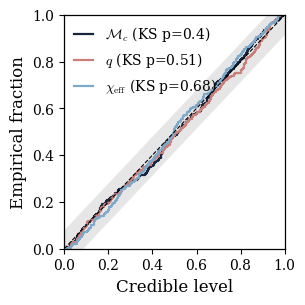

In [4]:
figures.fig_pp_3p(np.load('../data/results/pp_3p.npz'))

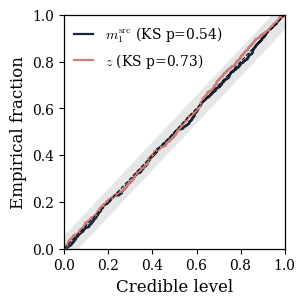

In [5]:
figures.fig_pp_2p(np.load('../data/results/pp_2p.npz'))